In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import joblib

from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

pd.set_option('display.max_columns', 30)

sns.set_theme(style='whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
files = list(Path('/kaggle/input').rglob('data.csv'))

if not files:
    raise FileNotFoundError("Please attach the Kaggle dataset.")

df = pd.read_csv(
    files[0],
    encoding='ISO-8859-1'
)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head(10))

Dataset loaded successfully
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nUnique Values:")
display(df.nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Statistical Summary:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN



Missing Values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Duplicate Records:
5268

Unique Values:


InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

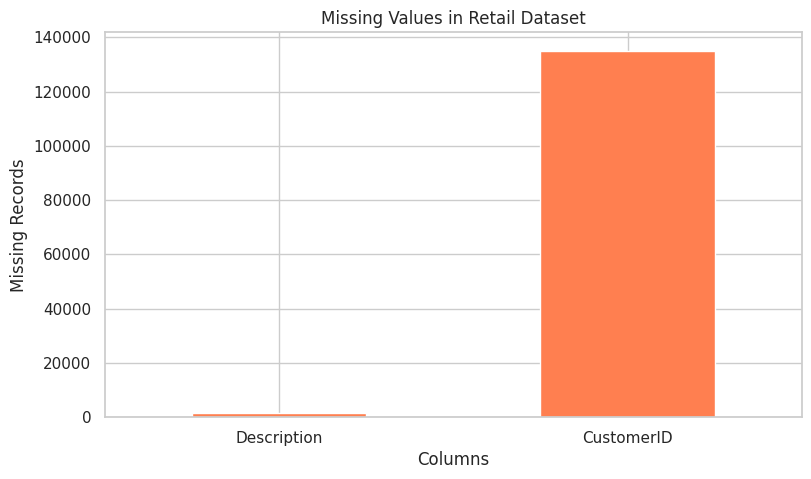

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0]

plt.figure(figsize=(9, 5))

missing.plot(
    kind='bar',
    color='coral'
)

plt.title("Missing Values in Retail Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Records")
plt.xticks(rotation=0)
plt.show()

In [5]:
clean = df.copy()

# Remove duplicate records
clean = clean.drop_duplicates()

# Standardize text columns
for col in ['InvoiceNo', 'StockCode', 'Country']:
    clean[col] = clean[col].astype('string').str.strip()

clean['Country'] = clean['Country'].replace(
    '', pd.NA
).fillna('Unknown')

# Convert date column
clean['InvoiceDate'] = pd.to_datetime(
    clean['InvoiceDate'],
    errors='coerce'
)

# Convert numerical columns
for col in ['Quantity', 'UnitPrice', 'CustomerID']:
    clean[col] = pd.to_numeric(
        clean[col],
        errors='coerce'
    )

# Remove cancelled invoices
clean = clean[
    ~clean['InvoiceNo'].str.startswith(
        'C', na=False
    )
]

# Remove invalid transactions
clean = clean[
    (clean['Quantity'] > 0) &
    (clean['UnitPrice'] > 0)
]

# Remove invalid essential fields
clean = clean.dropna(
    subset=['InvoiceNo', 'StockCode', 'InvoiceDate']
)

# Handle missing descriptions
clean['Description'] = (
    clean['Description']
    .astype('string')
    .str.strip()
    .str.upper()
    .replace('', pd.NA)
)

# Fill description using the same product code
clean['Description'] = clean['Description'].fillna(
    clean.groupby('StockCode')['Description']
    .transform('first')
)

clean['Description'] = clean['Description'].fillna(
    'UNKNOWN PRODUCT'
)

# Unknown customers are assigned ID -1
clean['CustomerID'] = (
    clean['CustomerID']
    .fillna(-1)
    .astype(int)
)

clean = clean.reset_index(drop=True)

print("Original records:", len(df))
print("Cleaned records:", len(clean))
print("Removed records:", len(df) - len(clean))

display(clean.head())

Original records: 541909
Cleaned records: 524878
Removed records: 17031


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Quantity outliers: 27111


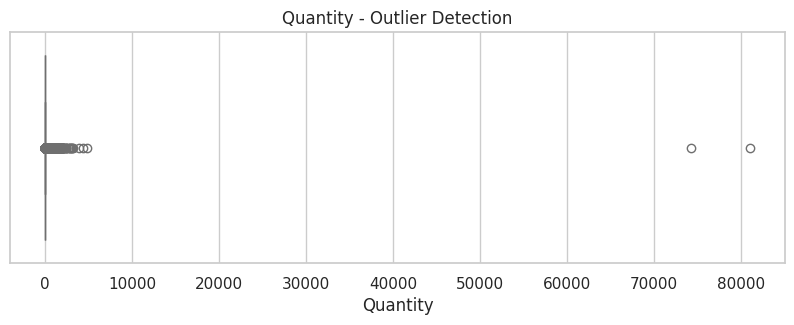

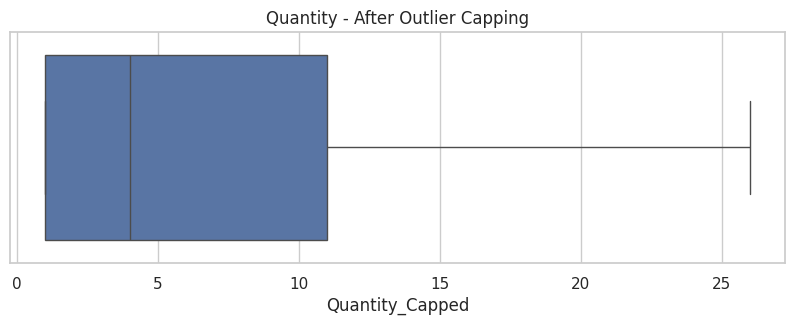

UnitPrice outliers: 37827


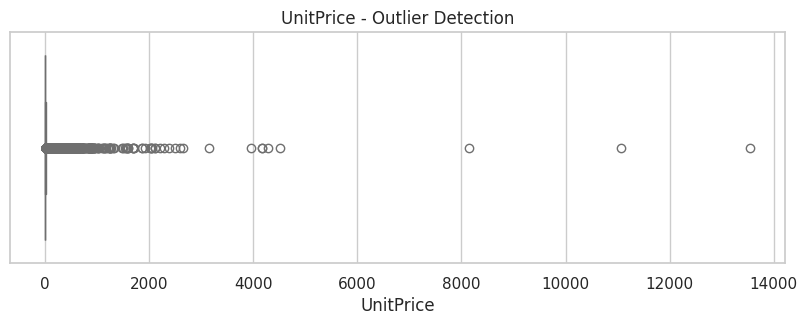

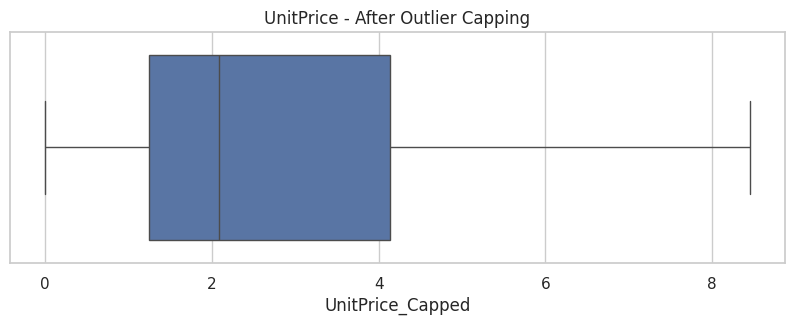

In [6]:
for col in ['Quantity', 'UnitPrice']:

    Q1 = clean[col].quantile(0.25)
    Q3 = clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (clean[col] < lower) |
        (clean[col] > upper)
    )

    clean[col + '_Outlier'] = outliers.astype(int)

    print(col, "outliers:", outliers.sum())

    # Visualization before handling
    plt.figure(figsize=(10, 3))
    sns.boxplot(x=clean[col], color='skyblue')
    plt.title(f"{col} - Outlier Detection")
    plt.show()

    # Capped copy for statistical analysis
    clean[col + '_Capped'] = clean[col].clip(
        lower=max(0, lower),
        upper=upper
    )

    plt.figure(figsize=(10, 3))
    sns.boxplot(x=clean[col + '_Capped'])
    plt.title(f"{col} - After Outlier Capping")
    plt.show()

In [7]:
clean['TotalSales'] = (
    clean['Quantity'] * clean['UnitPrice']
).round(2)

clean['Date'] = clean['InvoiceDate'].dt.date

clean['Year'] = clean['InvoiceDate'].dt.year
clean['Month'] = clean['InvoiceDate'].dt.month
clean['Quarter'] = clean['InvoiceDate'].dt.quarter

clean['MonthName'] = (
    clean['InvoiceDate'].dt.month_name()
)

clean['DayName'] = (
    clean['InvoiceDate'].dt.day_name()
)

clean['Hour'] = clean['InvoiceDate'].dt.hour

calendar = pd.DataFrame({
    'Month': range(1, 13),
    'Season': [
        'Winter', 'Winter',
        'Spring', 'Spring', 'Spring',
        'Summer', 'Summer', 'Summer',
        'Autumn', 'Autumn', 'Autumn',
        'Winter'
    ]
})

# Integrate transaction and calendar data
clean = clean.merge(
    calendar,
    on='Month',
    how='left',
    validate='many_to_one'
)

display(clean.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Quantity_Outlier,Quantity_Capped,UnitPrice_Outlier,UnitPrice_Capped,TotalSales,Date,Year,Month,Quarter,MonthName,DayName,Hour,Season
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,0,6,0,2.55,15.30,2010-12-01,2010,12,4,December,Wednesday,8,Winter
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,0,6,0,3.39,20.34,2010-12-01,2010,12,4,December,Wednesday,8,Winter
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,0,8,0,2.75,22.00,2010-12-01,2010,12,4,December,Wednesday,8,Winter
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,0,6,0,3.39,20.34,2010-12-01,2010,12,4,December,Wednesday,8,Winter
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,0,6,0,3.39,20.34,2010-12-01,2010,12,4,December,Wednesday,8,Winter


Before reduction: (524878, 21)
After reduction: (13067, 6)


,CustomerID,Year,Month,TotalSales,TotalQuantity,TotalOrders
0,-1,2010,12,251030.00,46971,159
1,-1,2011,1,121710.30,38626,99
2,-1,2011,2,76460.64,17907,103
3,-1,2011,3,122133.50,29017,133
4,-1,2011,4,68594.16,16587,97
5,-1,2011,5,91941.46,22137,126
6,-1,2011,6,100500.96,25497,140
7,-1,2011,7,119113.22,32333,144
8,-1,2011,8,113790.34,23647,81
9,-1,2011,9,105744.99,25921,82


,UnitPrice,PriceCategory,TotalSales,PurchaseCategory
0,2.55,Low,15.30,Small
1,3.39,Low,20.34,Small
2,2.75,Low,22.00,Small
3,3.39,Low,20.34,Small
4,3.39,Low,20.34,Small
5,7.65,Medium,15.30,Small
6,4.25,Low,25.50,Small
7,1.85,Low,11.10,Small
8,1.85,Low,11.10,Small
9,1.69,Low,54.08,Medium


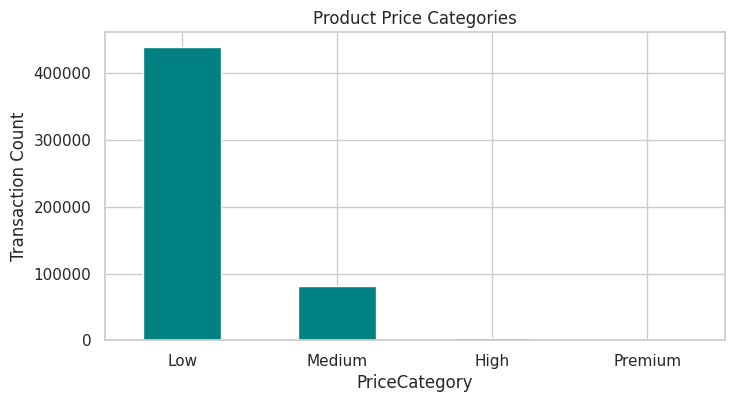

In [8]:
# Data reduction through aggregation

reduced_data = clean.groupby(
    ['CustomerID', 'Year', 'Month'],
    as_index=False
).agg(
    TotalSales=('TotalSales', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalOrders=('InvoiceNo', 'nunique')
)

print("Before reduction:", clean.shape)
print("After reduction:", reduced_data.shape)

display(reduced_data.head(10))

# Data discretization

clean['PriceCategory'] = pd.cut(
    clean['UnitPrice'],
    bins=[0, 5, 20, 100, np.inf],
    labels=['Low', 'Medium', 'High', 'Premium'],
    include_lowest=True
)

clean['PurchaseCategory'] = pd.cut(
    clean['TotalSales'],
    bins=[0, 50, 200, 1000, np.inf],
    labels=['Small', 'Medium', 'Large', 'Bulk'],
    include_lowest=True
)

display(clean[
    ['UnitPrice', 'PriceCategory',
     'TotalSales', 'PurchaseCategory']
].head(10))

clean['PriceCategory'].value_counts().plot(
    kind='bar',
    color='teal',
    figsize=(8, 4)
)

plt.title("Product Price Categories")
plt.ylabel("Transaction Count")
plt.xticks(rotation=0)
plt.show()

In [9]:
quality_report = pd.DataFrame({
    'Quality Check': [
        'Original Records',
        'Cleaned Records',
        'Duplicate Records',
        'Missing Values',
        'Invalid Quantity',
        'Invalid Unit Price',
        'Unknown Customer Records',
        'Inconsistent Sales Calculation'
    ],
    'Result': [
        len(df),
        len(clean),
        clean.duplicated().sum(),
        clean.isnull().sum().sum(),
        (clean['Quantity'] <= 0).sum(),
        (clean['UnitPrice'] <= 0).sum(),
        (clean['CustomerID'] == -1).sum(),
        (~np.isclose(
            clean['TotalSales'],
            clean['Quantity'] * clean['UnitPrice'],
            atol=0.005
        )).sum()
    ]
})

display(quality_report)

assert clean['Quantity'].gt(0).all()
assert clean['UnitPrice'].gt(0).all()
assert clean['InvoiceDate'].notna().all()

print("Essential data quality checks passed.")

,Quality Check,Result
0,Original Records,541909
1,Cleaned Records,524878
2,Duplicate Records,0
3,Missing Values,0
4,Invalid Quantity,0
5,Invalid Unit Price,0
6,Unknown Customer Records,132186
7,Inconsistent Sales Calculation,0


Essential data quality checks passed.


In [10]:
# Customer dimension

dim_customer = clean[
    ['CustomerID']
].drop_duplicates().reset_index(drop=True)

dim_customer['CustomerType'] = np.where(
    dim_customer['CustomerID'] == -1,
    'Unknown',
    'Identified'
)

# Product dimension

dim_product = (
    clean[['StockCode', 'Description']]
    .drop_duplicates('StockCode')
    .reset_index(drop=True)
)

dim_product.insert(
    0, 'ProductID',
    range(1, len(dim_product) + 1)
)

# Date dimension

dim_date = clean[
    ['Date', 'Year', 'Month', 'Quarter',
     'MonthName', 'DayName', 'Season']
].drop_duplicates().reset_index(drop=True)

dim_date.insert(
    0, 'DateKey',
    pd.to_datetime(dim_date['Date'])
    .dt.strftime('%Y%m%d')
    .astype(int)
)

# Country dimension

dim_country = clean[
    ['Country']
].drop_duplicates().reset_index(drop=True)

dim_country.insert(
    0, 'CountryID',
    range(1, len(dim_country) + 1)
)

print("Customer Dimension")
display(dim_customer.head())

print("Product Dimension")
display(dim_product.head())

print("Date Dimension")
display(dim_date.head())

print("Country Dimension")
display(dim_country.head())

Customer Dimension


,CustomerID,CustomerType
0,17850,Identified
1,13047,Identified
2,12583,Identified
3,13748,Identified
4,15100,Identified


Product Dimension


,ProductID,StockCode,Description
0,1,85123A,WHITE HANGING HEART T-LIGHT HOLDER
1,2,71053,WHITE METAL LANTERN
2,3,84406B,CREAM CUPID HEARTS COAT HANGER
3,4,84029G,KNITTED UNION FLAG HOT WATER BOTTLE
4,5,84029E,RED WOOLLY HOTTIE WHITE HEART.


Date Dimension


,DateKey,Date,Year,Month,Quarter,MonthName,DayName,Season
0,20101201,2010-12-01,2010,12,4,December,Wednesday,Winter
1,20101202,2010-12-02,2010,12,4,December,Thursday,Winter
2,20101203,2010-12-03,2010,12,4,December,Friday,Winter
3,20101205,2010-12-05,2010,12,4,December,Sunday,Winter
4,20101206,2010-12-06,2010,12,4,December,Monday,Winter


Country Dimension


,CountryID,Country
0,1,United Kingdom
1,2,France
2,3,Australia
3,4,Netherlands
4,5,Germany


In [11]:
fact_sales = clean.merge(
    dim_product[['ProductID', 'StockCode']],
    on='StockCode',
    validate='many_to_one'
)

fact_sales = fact_sales.merge(
    dim_date[['DateKey', 'Date']],
    on='Date',
    validate='many_to_one'
)

fact_sales = fact_sales.merge(
    dim_country,
    on='Country',
    validate='many_to_one'
)

fact_sales = fact_sales[[
    'InvoiceNo',
    'CustomerID',
    'ProductID',
    'DateKey',
    'CountryID',
    'Quantity',
    'UnitPrice',
    'TotalSales'
]].copy()

fact_sales.insert(
    0, 'SalesID',
    range(1, len(fact_sales) + 1)
)

assert len(fact_sales) == len(clean)

display(fact_sales.head(10))

,SalesID,InvoiceNo,CustomerID,ProductID,DateKey,CountryID,Quantity,UnitPrice,TotalSales
0,1,536365,17850,1,20101201,1,6,2.55,15.30
1,2,536365,17850,2,20101201,1,6,3.39,20.34
2,3,536365,17850,3,20101201,1,8,2.75,22.00
3,4,536365,17850,4,20101201,1,6,3.39,20.34
4,5,536365,17850,5,20101201,1,6,3.39,20.34
5,6,536365,17850,6,20101201,1,2,7.65,15.30
6,7,536365,17850,7,20101201,1,6,4.25,25.50
7,8,536366,17850,8,20101201,1,6,1.85,11.10
8,9,536366,17850,9,20101201,1,6,1.85,11.10
9,10,536367,13047,10,20101201,1,32,1.69,54.08


In [12]:
db_path = Path('/kaggle/working/retail_warehouse.db')

if db_path.exists():
    db_path.unlink()

conn = sqlite3.connect(db_path)

conn.execute("PRAGMA foreign_keys = ON")

conn.executescript("""
CREATE TABLE dim_customer (
    CustomerID INTEGER PRIMARY KEY,
    CustomerType TEXT
);

CREATE TABLE dim_product (
    ProductID INTEGER PRIMARY KEY,
    StockCode TEXT UNIQUE,
    Description TEXT
);

CREATE TABLE dim_date (
    DateKey INTEGER PRIMARY KEY,
    Date TEXT,
    Year INTEGER,
    Month INTEGER,
    Quarter INTEGER,
    MonthName TEXT,
    DayName TEXT,
    Season TEXT
);

CREATE TABLE dim_country (
    CountryID INTEGER PRIMARY KEY,
    Country TEXT UNIQUE
);

CREATE TABLE fact_sales (
    SalesID INTEGER PRIMARY KEY,
    InvoiceNo TEXT,
    CustomerID INTEGER,
    ProductID INTEGER,
    DateKey INTEGER,
    CountryID INTEGER,
    Quantity INTEGER CHECK(Quantity > 0),
    UnitPrice REAL CHECK(UnitPrice > 0),
    TotalSales REAL,

    FOREIGN KEY(CustomerID)
        REFERENCES dim_customer(CustomerID),

    FOREIGN KEY(ProductID)
        REFERENCES dim_product(ProductID),

    FOREIGN KEY(DateKey)
        REFERENCES dim_date(DateKey),

    FOREIGN KEY(CountryID)
        REFERENCES dim_country(CountryID)
);
""")

tables = {
    'dim_customer': dim_customer,
    'dim_product': dim_product,
    'dim_date': dim_date,
    'dim_country': dim_country,
    'fact_sales': fact_sales
}

for name, table in tables.items():
    table.to_sql(
        name,
        conn,
        if_exists='append',
        index=False
    )

conn.commit()

print("Data warehouse created successfully!")

display(pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
))

print(
    "Foreign key violations:",
    conn.execute("PRAGMA foreign_key_check").fetchall()
)

Data warehouse created successfully!


,name
0,dim_customer
1,dim_product
2,dim_date
3,dim_country
4,fact_sales


Foreign key violations: []


,Year,Revenue
0,2010,821452.73
1,2011,9820658.07


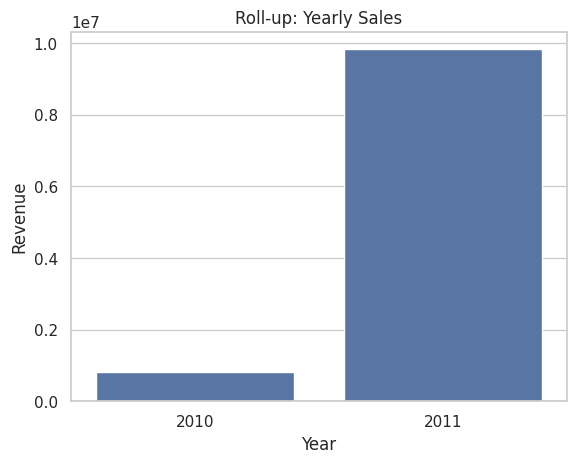

In [13]:
rollup = pd.read_sql_query("""
SELECT
    d.Year,
    ROUND(SUM(f.TotalSales), 2) AS Revenue
FROM fact_sales f
JOIN dim_date d
    ON f.DateKey = d.DateKey
GROUP BY d.Year
ORDER BY d.Year
""", conn)

display(rollup)

sns.barplot(
    data=rollup,
    x='Year',
    y='Revenue'
)

plt.title("Roll-up: Yearly Sales")
plt.show()

,Year,Quarter,Month,Revenue
0,2010,4,12,821452.73
1,2011,1,1,689811.61
2,2011,1,2,522545.56
3,2011,1,3,716215.26
4,2011,2,4,536968.49
5,2011,2,5,769296.61
6,2011,2,6,760547.01
7,2011,3,7,718076.12
8,2011,3,8,757841.38
9,2011,3,9,1056435.19


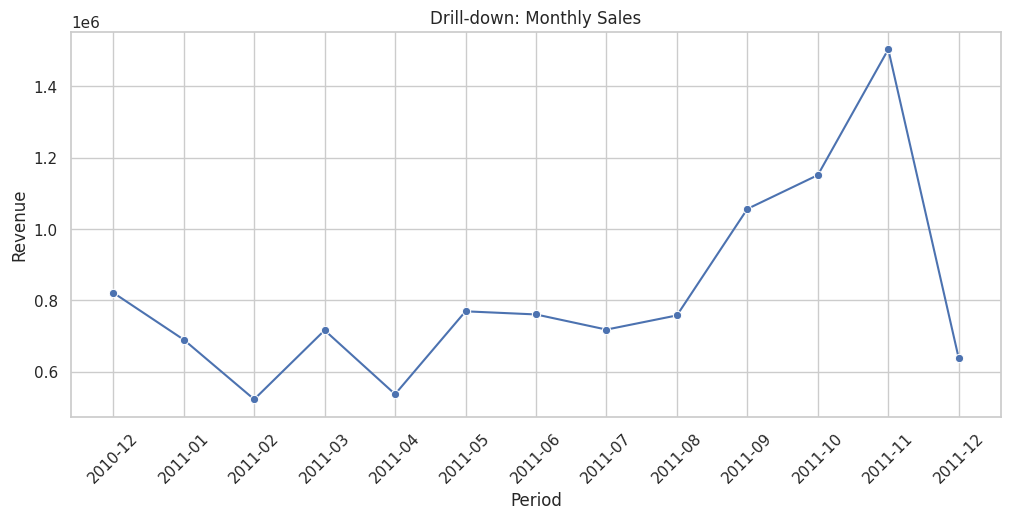

In [14]:
drilldown = pd.read_sql_query("""
SELECT
    d.Year,
    d.Quarter,
    d.Month,
    ROUND(SUM(f.TotalSales), 2) AS Revenue
FROM fact_sales f
JOIN dim_date d
    ON f.DateKey = d.DateKey
GROUP BY d.Year, d.Quarter, d.Month
ORDER BY d.Year, d.Month
""", conn)

display(drilldown)

drilldown['Period'] = (
    drilldown['Year'].astype(str) + '-' +
    drilldown['Month'].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=drilldown,
    x='Period',
    y='Revenue',
    marker='o'
)

plt.title("Drill-down: Monthly Sales")
plt.xticks(rotation=45)
plt.show()

In [15]:
slice_data = pd.read_sql_query("""
SELECT
    d.Year,
    d.Month,
    c.Country,
    ROUND(SUM(f.TotalSales), 2) AS Revenue
FROM fact_sales f
JOIN dim_country c
    ON f.CountryID = c.CountryID
JOIN dim_date d
    ON f.DateKey = d.DateKey
WHERE c.Country = 'United Kingdom'
GROUP BY d.Year, d.Month, c.Country
ORDER BY d.Year, d.Month
""", conn)

display(slice_data)

,Year,Month,Country,Revenue
0,2010,12,United Kingdom,746082.22
1,2011,1,United Kingdom,559975.83
2,2011,2,United Kingdom,428986.62
3,2011,3,United Kingdom,584810.78
4,2011,4,United Kingdom,475677.63
5,2011,5,United Kingdom,638104.89
6,2011,6,United Kingdom,618345.53
7,2011,7,United Kingdom,600919.07
8,2011,8,United Kingdom,606784.93
9,2011,9,United Kingdom,895098.64


In [16]:
dice_data = pd.read_sql_query("""
SELECT
    c.Country,
    d.Year,
    d.Month,
    ROUND(SUM(f.TotalSales), 2) AS Revenue
FROM fact_sales f
JOIN dim_country c
    ON f.CountryID = c.CountryID
JOIN dim_date d
    ON f.DateKey = d.DateKey
WHERE c.Country IN (
    'United Kingdom',
    'France',
    'Germany'
)
AND d.Year = 2011
AND d.Month BETWEEN 1 AND 6
GROUP BY c.Country, d.Year, d.Month
ORDER BY c.Country, d.Month
""", conn)

display(dice_data)

,Country,Year,Month,Revenue
0,France,2011,1,17740.12
1,France,2011,2,8515.96
2,France,2011,3,14584.95
3,France,2011,4,5529.61
4,France,2011,5,17606.48
5,France,2011,6,16348.41
6,Germany,2011,1,16880.84
7,Germany,2011,2,9581.05
8,Germany,2011,3,14392.69
9,Germany,2011,4,12315.54


Quarter,1,2,3,4
Country,,,,
Australia,40937.12,39597.78,32560.31,25358.60
Austria,2226.48,1930.21,2708.03,3333.96
Bahrain,0.00,548.40,0.00,205.74
Belgium,6733.25,8996.70,10237.61,15228.78
Brazil,0.00,1143.60,0.00,0.00
Canada,140.54,1705.70,1820.14,0.00
Channel Islands,5969.62,3560.27,6210.63,4700.02
Cyprus,5820.13,1109.32,196.35,6377.05
Czech Republic,549.26,0.00,0.00,277.48


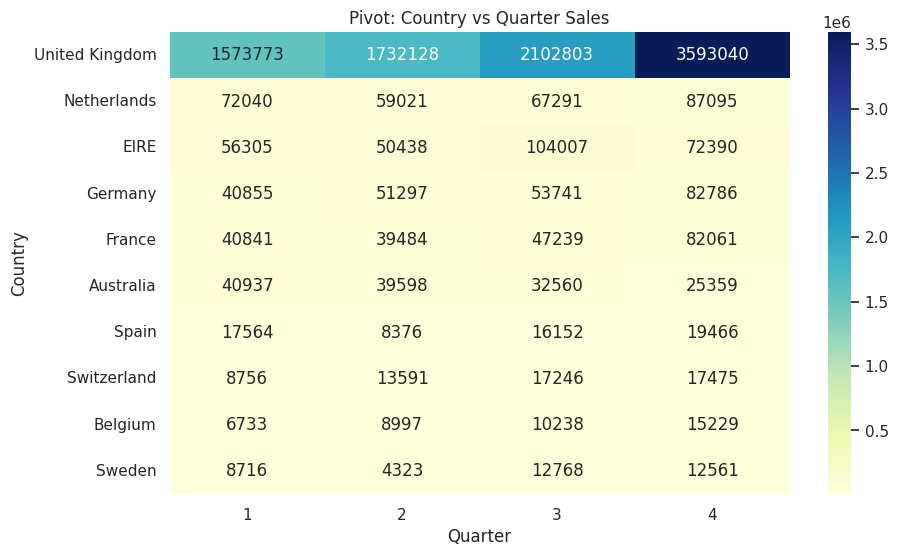

In [17]:
pivot_data = pd.pivot_table(
    clean,
    values='TotalSales',
    index='Country',
    columns='Quarter',
    aggfunc='sum',
    fill_value=0
)

display(pivot_data.round(2))

top_countries = (
    clean.groupby('Country')['TotalSales']
    .sum()
    .nlargest(10)
    .index
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_data.loc[top_countries],
    cmap='YlGnBu',
    annot=True,
    fmt='.0f'
)

plt.title("Pivot: Country vs Quarter Sales")
plt.show()

In [18]:
data_cube = pd.read_sql_query("""
SELECT
    d.Year,
    d.Quarter,
    c.Country,
    p.StockCode,
    ROUND(SUM(f.TotalSales), 2) AS Revenue,
    SUM(f.Quantity) AS TotalQuantity,
    COUNT(DISTINCT f.InvoiceNo) AS TotalOrders
FROM fact_sales f
JOIN dim_date d
    ON f.DateKey = d.DateKey
JOIN dim_country c
    ON f.CountryID = c.CountryID
JOIN dim_product p
    ON f.ProductID = p.ProductID
GROUP BY
    d.Year,
    d.Quarter,
    c.Country,
    p.StockCode
""", conn)

display(data_cube.head(20))

data_cube.to_sql(
    'sales_data_cube',
    conn,
    if_exists='replace',
    index=False
)

data_cube.to_csv(
    '/kaggle/working/sales_data_cube.csv',
    index=False
)

print("Data cube generated successfully!")
print("Cube shape:", data_cube.shape)

,Year,Quarter,Country,StockCode,Revenue,TotalQuantity,TotalOrders
0,2010,4,Australia,20685,31.8,4,1
1,2010,4,Australia,20725,16.5,10,1
2,2010,4,Australia,21622,39.6,8,1
3,2010,4,Australia,21791,15.0,12,1
4,2010,4,Australia,21906,27.0,4,1
5,2010,4,Australia,22191,17.0,2,1
6,2010,4,Australia,22192,17.0,2,1
7,2010,4,Australia,22193,17.0,2,1
8,2010,4,Australia,22195,59.4,36,2
9,2010,4,Australia,22196,40.8,48,2


Data cube generated successfully!
Cube shape: (41004, 7)


In [19]:
total_revenue = clean['TotalSales'].sum()

total_customers = clean.loc[
    clean['CustomerID'] != -1,
    'CustomerID'
].nunique()

total_orders = clean['InvoiceNo'].nunique()

total_products = clean['StockCode'].nunique()

average_order_value = total_revenue / total_orders

kpi = pd.DataFrame({
    'Business Metric': [
        'Total Revenue (GBP)',
        'Identified Customers',
        'Total Orders',
        'Total Products',
        'Average Order Value (GBP)'
    ],
    'Value': [
        total_revenue,
        total_customers,
        total_orders,
        total_products,
        average_order_value
    ]
})

display(kpi.round(2))

,Business Metric,Value
0,Total Revenue (GBP),10642110.80
1,Identified Customers,4338.00
2,Total Orders,19960.00
3,Total Products,3922.00
4,Average Order Value (GBP),533.17


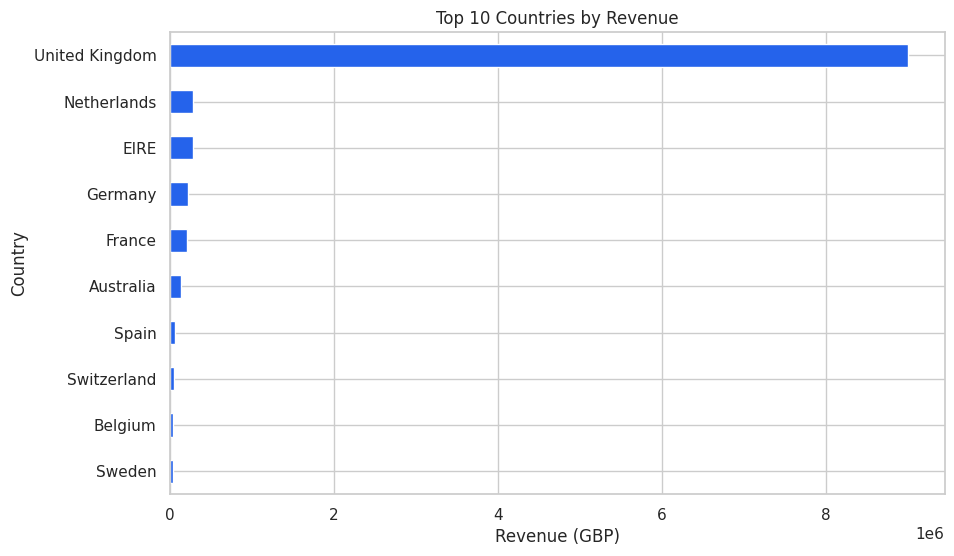

In [20]:
country_sales = (
    clean.groupby('Country')['TotalSales']
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

country_sales.plot(
    kind='barh',
    color='#2563eb'
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (GBP)")
plt.ylabel("Country")
plt.show()

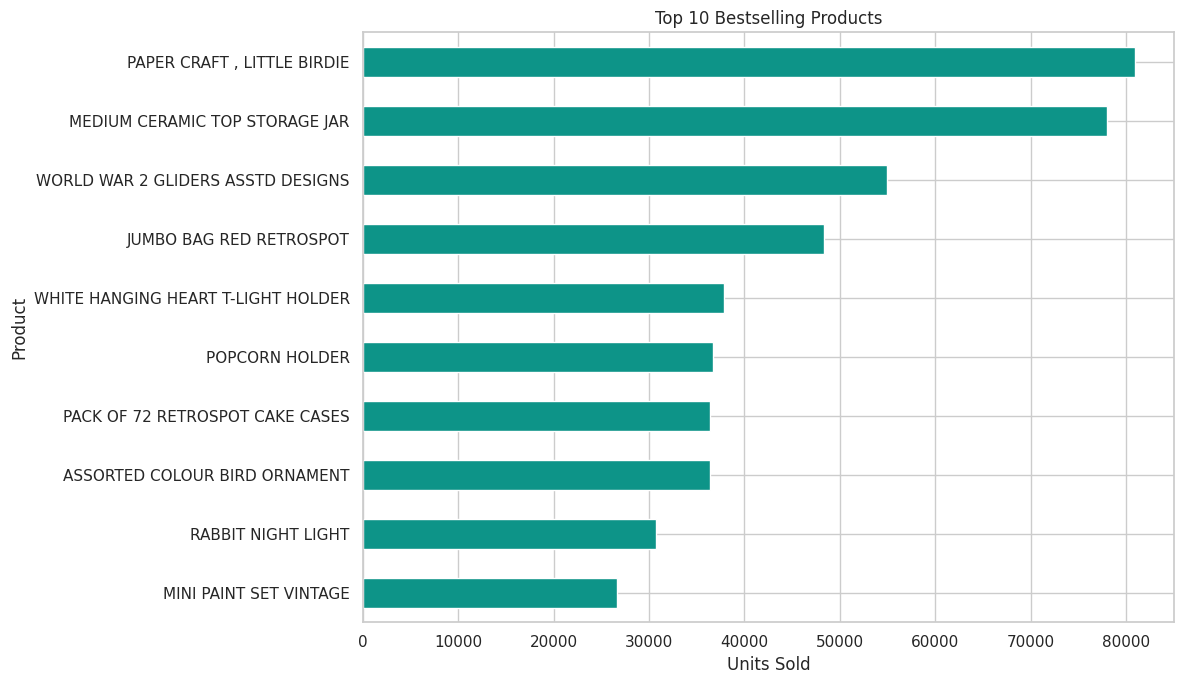

In [21]:
top_products = (
    clean.groupby('Description')['Quantity']
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))

top_products.plot(
    kind='barh',
    color='#0d9488'
)

plt.title("Top 10 Bestselling Products")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

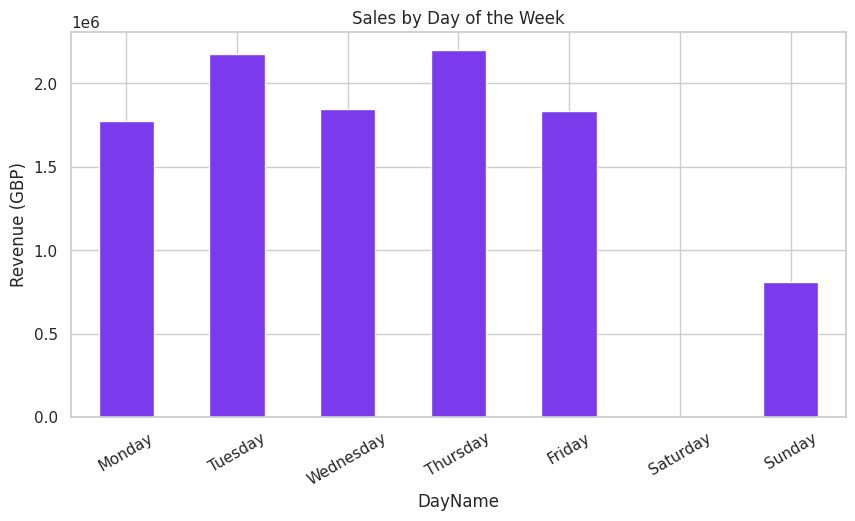

In [22]:
days = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday',
    'Sunday'
]

weekly_sales = (
    clean.groupby('DayName')['TotalSales']
    .sum()
    .reindex(days, fill_value=0)
)

plt.figure(figsize=(10, 5))

weekly_sales.plot(
    kind='bar',
    color='#7c3aed'
)

plt.title("Sales by Day of the Week")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=30)
plt.show()

In [23]:
customer_data = clean[
    clean['CustomerID'] != -1
].copy()

def create_customer_features(data, cutoff):

    cutoff = pd.Timestamp(cutoff)

    start_date = cutoff - pd.Timedelta(days=180)

    history = data[
        (data['InvoiceDate'] >= start_date) &
        (data['InvoiceDate'] < cutoff)
    ]

    features = history.groupby('CustomerID').agg(
        Recency=(
            'InvoiceDate',
            lambda x: (cutoff - x.max()).days
        ),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('TotalSales', 'sum'),
        Tenure=(
            'InvoiceDate',
            lambda x: (cutoff - x.min()).days
        ),
        TotalQuantity=('Quantity', 'sum'),
        UniqueProducts=('StockCode', 'nunique')
    )

    features['AvgOrderValue'] = (
        features['Monetary'] /
        features['Frequency']
    )

    return features.reset_index()


def create_churn_dataset(data, cutoff):

    cutoff = pd.Timestamp(cutoff)

    features = create_customer_features(
        data, cutoff
    )

    future_end = cutoff + pd.Timedelta(days=60)

    future = data[
        (data['InvoiceDate'] >= cutoff) &
        (data['InvoiceDate'] < future_end)
    ]

    active_customers = future[
        'CustomerID'
    ].unique()

    features['Churn'] = (
        ~features['CustomerID']
        .isin(active_customers)
    ).astype(int)

    return features


# Historical training snapshot
train_data = create_churn_dataset(
    customer_data,
    '2011-06-01'
)

# Later testing snapshot
test_data = create_churn_dataset(
    customer_data,
    '2011-10-01'
)

print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)

display(train_data.head(10))

Training dataset: (2659, 9)
Testing dataset: (2925, 9)


,CustomerID,Recency,Frequency,Monetary,Tenure,TotalQuantity,UniqueProducts,AvgOrderValue,Churn
0,12346,133,1,77183.60,133,74215,1,77183.600000,1
1,12347,54,3,1823.43,175,1117,63,607.810000,0
2,12348,56,3,1487.24,166,2124,22,495.746667,1
3,12350,118,1,334.40,118,197,17,334.400000,1
4,12352,70,5,1561.81,104,254,26,312.362000,1
5,12353,12,1,89.00,12,20,4,89.000000,1
6,12354,40,1,1079.40,40,530,58,1079.400000,1
7,12355,22,1,459.40,22,240,13,459.400000,1
8,12356,53,2,2753.08,133,1586,53,1376.540000,1
9,12359,113,2,2386.41,139,609,93,1193.205000,0


Churn Distribution:


Churn
1    1529
0    1130
Name: count, dtype: int64

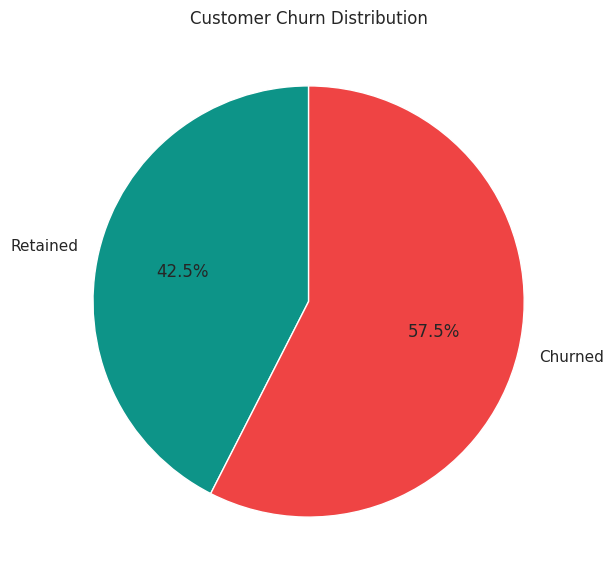

In [24]:
churn_counts = train_data['Churn'].value_counts()

print("Churn Distribution:")
display(churn_counts)

plt.figure(figsize=(7, 7))

plt.pie(
    [
        churn_counts.get(0, 0),
        churn_counts.get(1, 0)
    ],
    labels=['Retained', 'Churned'],
    autopct='%1.1f%%',
    colors=['#0d9488', '#ef4444'],
    startangle=90
)

plt.title("Customer Churn Distribution")
plt.show()

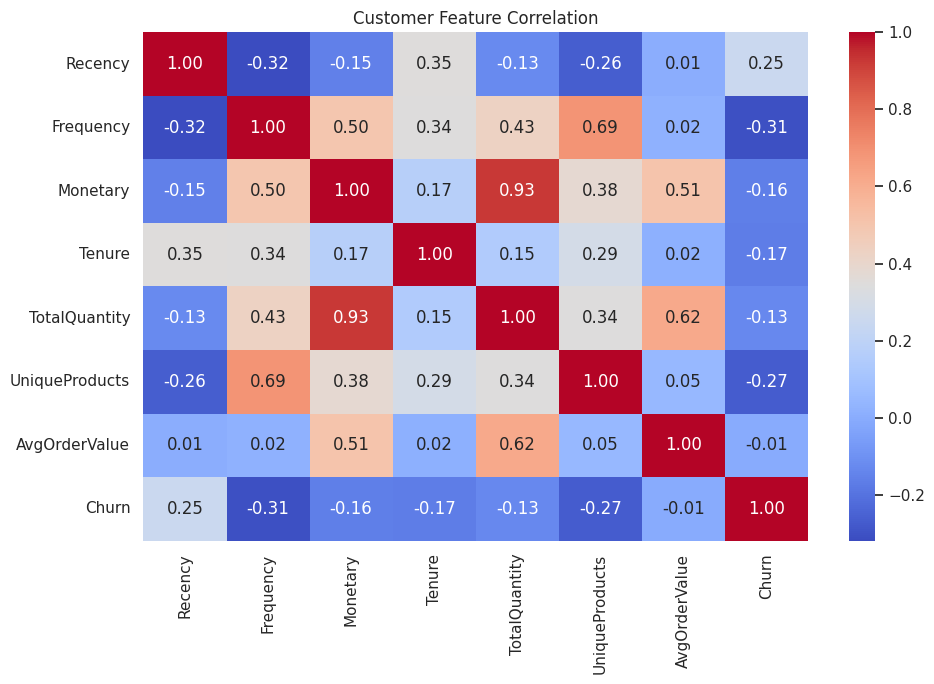

In [25]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    train_data.drop(
        columns='CustomerID'
    ).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Customer Feature Correlation")
plt.tight_layout()
plt.show()

In [26]:
feature_columns = [
    'Recency',
    'Frequency',
    'Monetary',
    'Tenure',
    'TotalQuantity',
    'UniqueProducts',
    'AvgOrderValue'
]

X_train = train_data[feature_columns]
y_train = train_data['Churn']

X_test = test_data[feature_columns]
y_test = test_data['Churn']

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts())

Training features: (2659, 7)
Testing features: (2925, 7)

Training label distribution:
Churn
1    1529
0    1130
Name: count, dtype: int64


In [27]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_probability = rf_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest trained successfully!")

print(
    "Accuracy:",
    accuracy_score(y_test, rf_predictions)
)

Random Forest trained successfully!
Accuracy: 0.6567521367521367


In [28]:
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    )
)

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

lr_probability = lr_model.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression trained successfully!")

print(
    "Accuracy:",
    accuracy_score(y_test, lr_predictions)
)

Logistic Regression trained successfully!
Accuracy: 0.6577777777777778


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.6568,0.6092,0.7716,0.6809,0.7146
1,Logistic Regression,0.6578,0.6065,0.7939,0.6877,0.7248


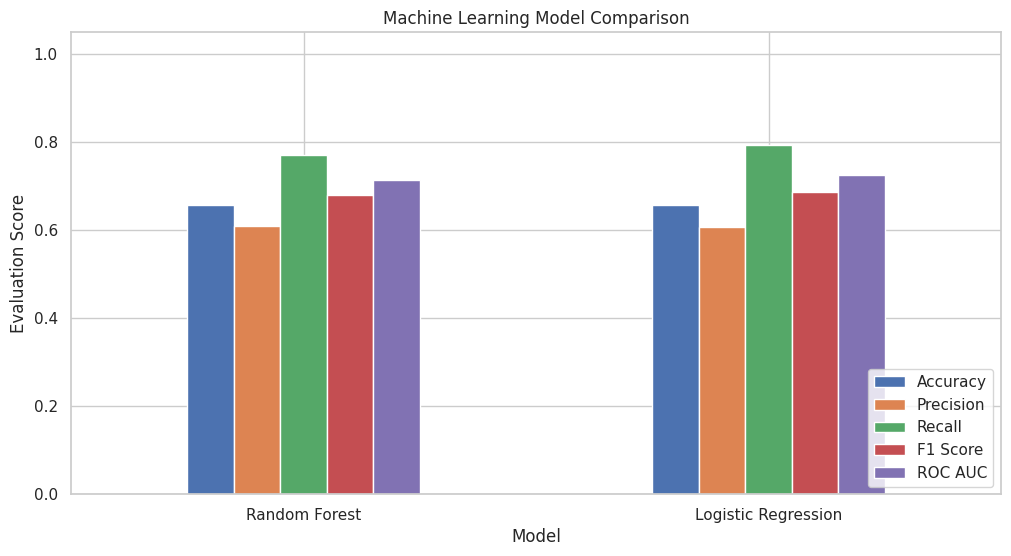

In [29]:
def evaluate_model(name, predictions, probability):

    return {
        'Model': name,
        'Accuracy': accuracy_score(
            y_test, predictions
        ),
        'Precision': precision_score(
            y_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, predictions, zero_division=0
        ),
        'ROC AUC': roc_auc_score(
            y_test, probability
        )
    }


results = pd.DataFrame([
    evaluate_model(
        'Random Forest',
        rf_predictions,
        rf_probability
    ),
    evaluate_model(
        'Logistic Regression',
        lr_predictions,
        lr_probability
    )
])

display(results.round(4))

results.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

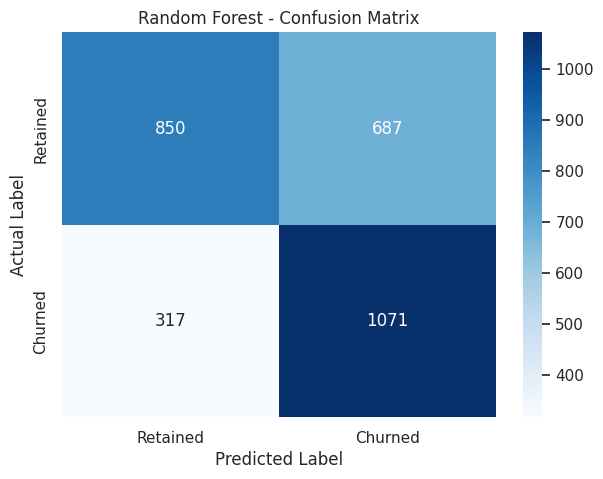

              precision    recall  f1-score   support

           0       0.73      0.55      0.63      1537
           1       0.61      0.77      0.68      1388

    accuracy                           0.66      2925
   macro avg       0.67      0.66      0.65      2925
weighted avg       0.67      0.66      0.65      2925



In [30]:
cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

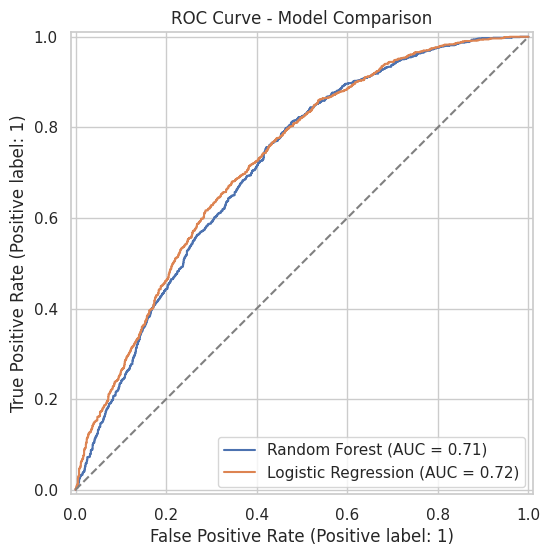

In [31]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    rf_probability,
    name='Random Forest',
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    lr_probability,
    name='Logistic Regression',
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray'
)

plt.title("ROC Curve - Model Comparison")
plt.show()

,Feature,Importance
2,Monetary,0.192681
4,TotalQuantity,0.176179
1,Frequency,0.161179
0,Recency,0.129611
5,UniqueProducts,0.129072
6,AvgOrderValue,0.112391
3,Tenure,0.098886


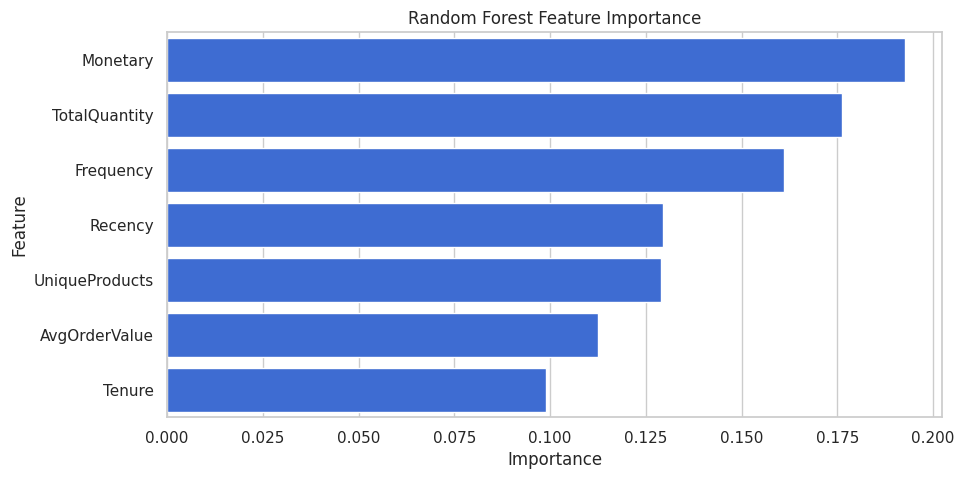

In [32]:
importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': rf_model.feature_importances_
}).sort_values(
    'Importance',
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    color='#2563eb'
)

plt.title("Random Forest Feature Importance")
plt.show()

In [33]:
combined = pd.concat(
    [train_data, test_data],
    ignore_index=True
)

final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    combined[feature_columns],
    combined['Churn']
)

latest_cutoff = (
    customer_data['InvoiceDate'].max()
    .normalize() + pd.Timedelta(days=1)
)

customer_predictions = create_customer_features(
    customer_data,
    latest_cutoff
)

customer_predictions['ChurnProbability'] = (
    final_model.predict_proba(
        customer_predictions[feature_columns]
    )[:, 1]
)

customer_predictions['PredictedChurn'] = (
    customer_predictions['ChurnProbability'] >= 0.5
).astype(int)

customer_predictions['RiskLevel'] = pd.cut(
    customer_predictions['ChurnProbability'],
    bins=[-0.01, 0.3, 0.7, 1],
    labels=['Low', 'Medium', 'High']
)

customer_predictions = (
    customer_predictions.sort_values(
        'ChurnProbability',
        ascending=False
    )
)

display(customer_predictions.head(20))

,CustomerID,Recency,Frequency,Monetary,Tenure,TotalQuantity,UniqueProducts,AvgOrderValue,ChurnProbability,PredictedChurn,RiskLevel
3247,17879,173,1,178.52,173,45,6,178.52,0.896254,1,High
2333,16320,172,1,185.78,172,78,9,185.78,0.887622,1,High
1534,14958,147,1,107.40,147,20,8,107.40,0.884853,1,High
3461,18260,172,1,427.13,172,177,23,427.13,0.880861,1,High
1800,15412,171,1,190.53,171,108,10,190.53,0.875920,1,High
2053,15825,172,1,532.94,172,220,20,532.94,0.874080,1,High
877,13826,176,1,189.50,176,82,10,189.50,0.873368,1,High
939,13929,169,1,429.80,169,100,7,429.80,0.870876,1,High
950,13947,65,1,90.60,65,44,5,90.60,0.870046,1,High
635,13403,17,1,75.00,17,44,3,75.00,0.866959,1,High


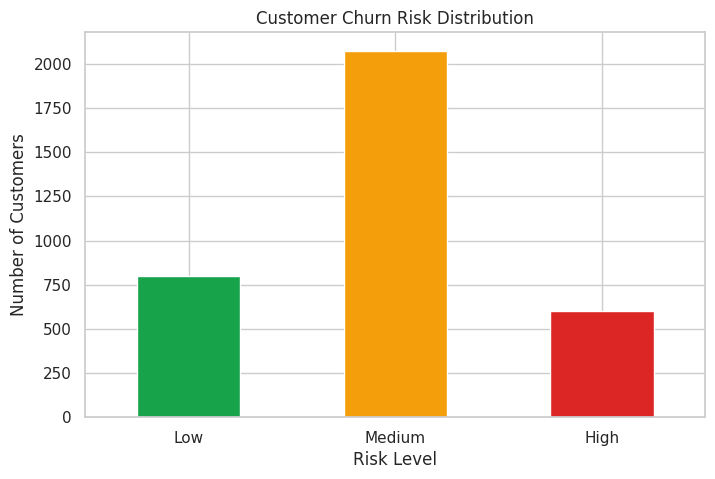

RiskLevel
Low        801
Medium    2075
High       601
Name: count, dtype: int64

In [34]:
risk_counts = (
    customer_predictions['RiskLevel']
    .value_counts()
    .reindex(['Low', 'Medium', 'High'])
    .fillna(0)
)

plt.figure(figsize=(8, 5))

risk_counts.plot(
    kind='bar',
    color=['#16a34a', '#f59e0b', '#dc2626']
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

display(risk_counts)

In [35]:
def predict_customer_churn(
    recency,
    frequency,
    monetary,
    tenure,
    total_quantity,
    unique_products,
    avg_order_value
):

    customer = pd.DataFrame([[
        recency,
        frequency,
        monetary,
        tenure,
        total_quantity,
        unique_products,
        avg_order_value
    ]], columns=feature_columns)

    probability = final_model.predict_proba(
        customer
    )[0, 1]

    if probability >= 0.7:
        risk = 'High Risk'
    elif probability > 0.3:
        risk = 'Medium Risk'
    else:
        risk = 'Low Risk'

    print("Customer Churn Prediction")
    print("---------------------------")
    print(f"Churn Probability: {probability:.2%}")
    print("Risk Level:", risk)

    return probability


predict_customer_churn(
    recency=120,
    frequency=2,
    monetary=150,
    tenure=170,
    total_quantity=20,
    unique_products=8,
    avg_order_value=75
)

Customer Churn Prediction
---------------------------
Churn Probability: 75.42%
Risk Level: High Risk


np.float64(0.7541521384447475)

In [36]:
best_country = (
    clean.groupby('Country')['TotalSales']
    .sum()
    .idxmax()
)

best_product = (
    clean.groupby('Description')['Quantity']
    .sum()
    .idxmax()
)

monthly_revenue = clean.groupby(
    clean['InvoiceDate'].dt.to_period('M')
)['TotalSales'].sum()

best_month = monthly_revenue.idxmax()

high_risk = (
    customer_predictions['RiskLevel'] == 'High'
).sum()

best_evaluated_model = results.loc[
    results['F1 Score'].idxmax(),
    'Model'
]

print("========== BUSINESS INSIGHTS ==========")

print("Highest revenue country:", best_country)
print("Bestselling product:", best_product)
print("Highest revenue month:", best_month)
print("High-risk customers:", high_risk)

print(
    "Best evaluated model by F1:",
    best_evaluated_model
)

print(
    "Total revenue:",
    f"£{total_revenue:,.2f}"
)

========== BUSINESS INSIGHTS ==========
Highest revenue country: United Kingdom
Bestselling product: PAPER CRAFT , LITTLE BIRDIE
Highest revenue month: 2011-11
High-risk customers: 601
Best evaluated model by F1: Logistic Regression
Total revenue: £10,642,110.80


In [37]:
output = Path('/kaggle/working')

clean.to_csv(
    output / 'cleaned_retail_data.csv',
    index=False
)

customer_predictions.to_csv(
    output / 'customer_churn_predictions.csv',
    index=False
)

results.to_csv(
    output / 'model_evaluation.csv',
    index=False
)

quality_report.to_csv(
    output / 'data_quality_report.csv',
    index=False
)

kpi.to_csv(
    output / 'business_kpis.csv',
    index=False
)

importance.to_csv(
    output / 'feature_importance.csv',
    index=False
)

joblib.dump(
    final_model,
    output / 'customer_churn_model.pkl'
)

joblib.dump(
    lr_model,
    output / 'logistic_regression_model.pkl'
)

conn.close()

print("All project files exported successfully!")

for file in output.iterdir():
    print(file.name)

All project files exported successfully!
__notebook__.ipynb
cleaned_retail_data.csv
logistic_regression_model.pkl
sales_data_cube.csv
model_evaluation.csv
retail_warehouse.db
customer_churn_predictions.csv
business_kpis.csv
data_quality_report.csv
customer_churn_model.pkl
feature_importance.csv


## Conclusion

The AI-Based Retail Customer Analytics, Data Warehouse and Churn Prediction System demonstrates an integrated approach to transforming raw retail transaction data into meaningful business intelligence.

The project implements data cleaning, missing value treatment, outlier detection, data integration, transformation, reduction, discretization and data quality validation.

A relational data warehouse based on a star schema was designed using SQLite. Multidimensional data analysis was performed using OLAP operations, including Roll-up, Drill-down, Slice, Dice and Pivot, along with data cube generation.

Random Forest and Logistic Regression algorithms were implemented to predict customer churn using historical purchasing behavior. The models were evaluated using accuracy, precision, recall, F1 score, ROC-AUC and confusion matrices.

The system supports customer retention planning, sales analysis, inventory optimization and data-driven business decision-making.

Future improvements may include real-time transaction integration, automated ETL pipelines, interactive business intelligence dashboards, improved churn probability calibration and personalized customer retention strategies.